---
title: "Week 4 Homework"
subtitle: DS 2023 | Communicating with Data
---

## Overview

In Week 4 you rebuilt the **Hertzsprung-Russell diagram** from Gaia data: a scatter plot in which
thousands of stars, plotted by color against absolute magnitude, stop being a cloud and resolve into
a **main sequence**, a giant branch, and a scattering of white dwarfs.

This homework asks you to do the same thing with countries.

In 1975 the economist **Samuel Preston** plotted national income against life expectancy and found the
same kind of structure: not a random cloud, but a curved band with a handful of conspicuous
departures from it. 

Hans Rosling later turned that plot into the most famous statistical graphic of
the last thirty years, and named his foundation after the warning you hear on the London
Underground: **Gapminder**.

Your job is to build that diagram, and to do the exploratory work that earns you the right to
draw it.

> [!NOTE] The H-R diagram and the Preston curve share a common structure.
>
> Both plot a **derived** quantity (absolute magnitude; GDP per capita) against an **observed** one
> (color index; life expectancy).
>
> Both need a **logarithmic** axis, because the underlying
> quantity spans several orders of magnitude. And in both, the scientific payoff is in the
> **shape of the point cloud**, not in any single point.

## Submitting your work 

After completing all the tasks in this notebook, restart the kernel and run all cells top to bottom before you submit. Make sure that all outputs are present and there are no errors.

Push the completed notebook to your GitHub repository and submit the URL to the homework assignment on Canvas.

## The data set

The **Gapminder** data set ships with Plotly Express. 

It contains $1{,}704$ observations: one row per country per year, for $142$ countries observed every five years from $1952$ to $2007$.

Here is the data dictionary:

| Column | Units | Description |
|---|---|---|
| `country` | — | Country name. |
| `continent` | — | One of `Africa`, `Americas`, `Asia`, `Europe`, `Oceania`. |
| `year` | year | Year of observation. Every fifth year, $1952$ through $2007$. |
| `lifeExp` | years | Life expectancy at birth. |
| `pop` | people | Total population. |
| `gdpPercap` | international dollars | GDP per capita, inflation-adjusted and PPP-adjusted so that values are comparable across countries and years. |
| `iso_alpha` | — | Three-letter ISO country code. |
| `iso_num` | — | Numeric ISO country code. We drop this one. |

To get the data, do this:

```python
from plotly.express import data as pxdata
gap = pxdata.gapminder()
```

## Tasks

Each task is worth 1 point.

Fractions will be given for partial credit.

### Task 1 

**Load and inspect the data.**

1. Import `pandas` as `pd`, `numpy` as `np`, `matplotlib.pyplot` as `plt`, and `seaborn` as `sns`.
2. Load the Gapminder data into a dataframe named `gap` and drop the `iso_num` column.
3. Display `.info()` and `.head()`.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
from plotly.express import data as pxdata
gap = pxdata.gapminder()

In [9]:
gap = gap.drop(columns=['iso_num'])

gap.info()
gap.head()

<class 'pandas.DataFrame'>
RangeIndex: 1704 entries, 0 to 1703
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   country    1704 non-null   str    
 1   continent  1704 non-null   str    
 2   year       1704 non-null   int64  
 3   lifeExp    1704 non-null   float64
 4   pop        1704 non-null   int64  
 5   gdpPercap  1704 non-null   float64
 6   iso_alpha  1704 non-null   str    
dtypes: float64(2), int64(2), str(3)
memory usage: 122.0 KB


,country,continent,year,lifeExp,pop,gdpPercap,iso_alpha
0,Afghanistan,Asia,1952,28.801,8425333,779.445314,AFG
1,Afghanistan,Asia,1957,30.332,9240934,820.853030,AFG
2,Afghanistan,Asia,1962,31.997,10267083,853.100710,AFG
3,Afghanistan,Asia,1967,34.020,11537966,836.197138,AFG
4,Afghanistan,Asia,1972,36.088,13079460,739.981106,AFG


**Question.** Is this table tidy or wide? What is the unit of observation — that is, what does
a single row represent? Answer in one or two sentences.

**Answer:** The table is tidy because each row represents a single unit of obsevation. The unit of observation is the country in a given year.

### Task 2 

**Create derived columns**


In Week 4 you could not plot the H-R diagram until you turned apparent magnitude into **absolute**
magnitude, because a nearby dim star and a distant brilliant one can look equally bright. The same
move is needed here: raw numbers have to be converted into quantities that are comparable across
countries of wildly different sizes.

Add three columns to `gap`:

1. `gdp_total`: total GDP, computed as `gdpPercap * pop`.
2. `log_gdppc`: the base-$10$ logarithm of GDP per capita, computed with `np.log10()`.
3. `pop_m`: population in millions.

Then display the first five rows and answer the question.

In [40]:
gap['gdp_total']= (gap['gdpPercap'] * gap['pop'])
gap['log_gdppc']= np.log10(gap['gdpPercap'])
gap['pop_m'] =(gap['pop'] / 1000000)

gap

,country,continent,year,lifeExp,pop,gdpPercap,iso_alpha,gdp_total,log_gdppc,pop_m
0,Afghanistan,Asia,1952,28.801,8425333,779.445314,AFG,6.567086e+09,2.891786,8.425333
1,Afghanistan,Asia,1957,30.332,9240934,820.853030,AFG,7.585449e+09,2.914265,9.240934
2,Afghanistan,Asia,1962,31.997,10267083,853.100710,AFG,8.758856e+09,2.931000,10.267083
3,Afghanistan,Asia,1967,34.020,11537966,836.197138,AFG,9.648014e+09,2.922309,11.537966
4,Afghanistan,Asia,1972,36.088,13079460,739.981106,AFG,9.678553e+09,2.869221,13.079460
...,...,...,...,...,...,...,...,...,...,...
1699,Zimbabwe,Africa,1987,62.351,9216418,706.157306,ZWE,6.508241e+09,2.848901,9.216418
1700,Zimbabwe,Africa,1992,60.377,10704340,693.420786,ZWE,7.422612e+09,2.840997,10.704340
1701,Zimbabwe,Africa,1997,46.809,11404948,792.449960,ZWE,9.037851e+09,2.898972,11.404948
1702,Zimbabwe,Africa,2002,39.989,11926563,672.038623,ZWE,8.015111e+09,2.827394,11.926563


**Question.** In $2007$, China's `gdpPercap` is about $4{,}959$ and Norway's is about $49{,}357$. Which of the two has the larger `gdp_total`? 

Consider and keep as a mental note what this tells you about why we plot `gdpPercap` rather than `gdp_total` against life expectancy.

**Answer:**
China has a larger gdp_total because its population is greater than that of Norway's, and the gdp_total is calculated by multiplying by gdpPercap with the population.


### Task 3 

**Finding the extremes.** 

When you built the H-R diagram you used `.nsmallest()` to find the closest star in the sample.
Do the same kind of reconnaissance here.

1. Create a dataframe `gap07` containing only the observations from $2007$. Use `.query()`.
2. Show the five countries with the **highest** life expectancy in $2007$, along with their
   `gdpPercap`.
3. Show the five countries with the **lowest** life expectancy in $2007$, along with their
   `gdpPercap`.
4. Show the five countries with the **highest** `gdpPercap` in $2007$.

In [43]:
gap07 = gap.query("year==2007")
gap07_highestlifeExp = gap07.nlargest(5, "lifeExp")[["country","lifeExp","gdpPercap"]]
gap07_lowestlifeExp = gap07.nsmallest(5, "lifeExp")[["country","lifeExp","gdpPercap"]]
gap07_highestgdpPercap = gap07.nlargest(5, "gdpPercap")[["country","lifeExp","gdpPercap"]]

(               country  lifeExp    gdpPercap
 803              Japan   82.603  31656.06806
 671   Hong Kong, China   82.208  39724.97867
 695            Iceland   81.757  36180.78919
 1487       Switzerland   81.701  37506.41907
 71           Australia   81.235  34435.36744,
            country  lifeExp    gdpPercap
 1463     Swaziland   39.613  4513.480643
 1043    Mozambique   42.082   823.685621
 1691        Zambia   42.384  1271.211593
 1355  Sierra Leone   42.568   862.540756
 887        Lesotho   42.592  1569.331442,
             country  lifeExp    gdpPercap
 1151         Norway   80.196  49357.19017
 863          Kuwait   77.588  47306.98978
 1367      Singapore   79.972  47143.17964
 1619  United States   78.242  42951.65309
 755         Ireland   78.885  40675.99635)

In [44]:
gap07_highestlifeExp

,country,lifeExp,gdpPercap
803,Japan,82.603,31656.06806
671,"Hong Kong, China",82.208,39724.97867
695,Iceland,81.757,36180.78919
1487,Switzerland,81.701,37506.41907
71,Australia,81.235,34435.36744


In [45]:
gap07_lowestlifeExp

,country,lifeExp,gdpPercap
1463,Swaziland,39.613,4513.480643
1043,Mozambique,42.082,823.685621
1691,Zambia,42.384,1271.211593
1355,Sierra Leone,42.568,862.540756
887,Lesotho,42.592,1569.331442


In [46]:
gap07_highestgdpPercap

,country,lifeExp,gdpPercap
1151,Norway,80.196,49357.19017
863,Kuwait,77.588,47306.98978
1367,Singapore,79.972,47143.17964
1619,United States,78.242,42951.65309
755,Ireland,78.885,40675.99635


**Question.** At least one country appears in the richest five but not in the longest-lived five.
Name it and say what that mismatch suggests about the relationship you are about to plot.

**Answer:** Norway appears in the richest five but not in the longest-lived five. This mismatch suggests that being richer does not necessarily mean a population will live for longer.

### Task 4 

**Composition: pie and bar charts.**

Work with `gap07` for this task.

1. Create a pie chart of the number of countries per continent.
2. Recreate the pie chart with the **largest** wedge exploded by $0.1$ and the start angle set to
   $90$ degrees. Build the explode list programmatically — do not hard-code the number of
   continents.
3. Create a bar chart of the **mean** `lifeExp` by continent, sorted from lowest to highest, with
   horizontal x tick labels.
4. Add value labels to the top of each bar, formatted to one decimal place.

> [!tip] For the labels: `ax.bar_label(ax.containers[0], fmt='%.1f')`

<Axes: >

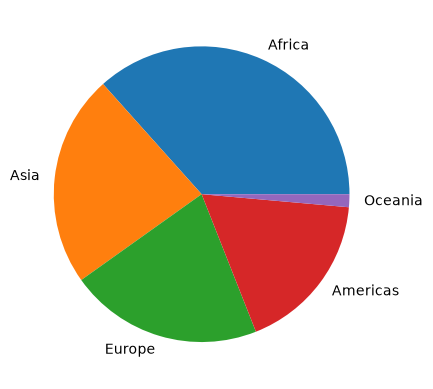

In [47]:
countries_per_continent = gap07['continent'].value_counts()
countries_per_continent.plot.pie()

In [66]:
countries_per_continent
explode_list = [0 for i in range(len(countries_per_continent))]
explode_list[0] = .1
explode_list

[0.1, 0, 0, 0, 0]

In [67]:
countries_per_continent.idxmax()

'Africa'

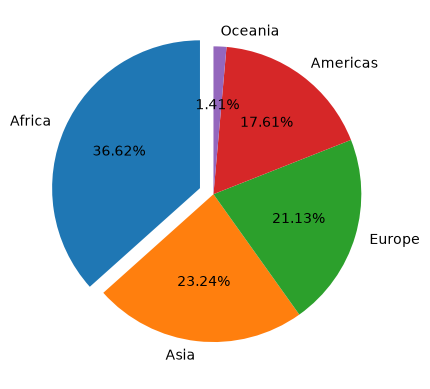

In [83]:
countries_per_continent.plot.pie(explode=explode_list, startangle=90, autopct='%1.2f%%')
plt.show()

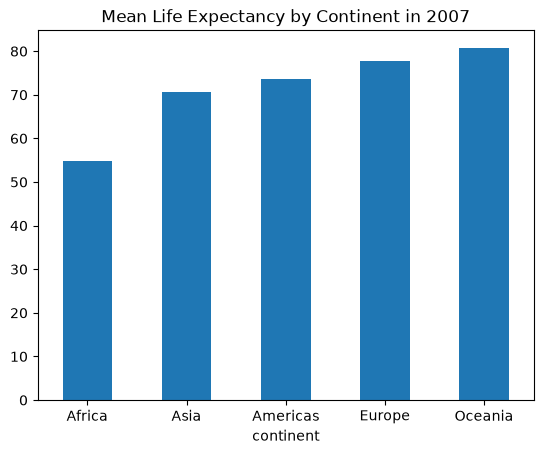

In [80]:
lifeExp = gap07.groupby('continent')['lifeExp'].mean().sort_values()
lifeExp.plot.bar(rot=0, title="Mean Life Expectancy by Continent in 2007")
plt.show()



**Question.** The pie chart and the bar chart both describe continents, but they answer different
questions. State the question each one answers, and explain why the pie chart would be the wrong
chart for the mean life expectancy figures.

**Answer:**

The pie chart answers: "What percentage of total countries belong to a particular continent?"
The bar chart answers: "What is the mean life expectancy, in years, for each continent in 2007?"

The pie chart would be the wrong chart for mean life expectancy figures because it only works for parts of a whole that sum to 100%. The mean life expectancy figures are independent averages that sum to an integer or float greater than 100%, not parts of a percentage that add to 100% like with the pie chart.

### Task 5 

**Grouped bar charts**

1. Create a dataframe holding the mean `lifeExp` for each combination of `continent` and `year`,
   restricted to the years $1952$, $1977$, and $2007$. Use `.groupby()` with `.unstack()`, or
   `.pivot_table()`.
2. Plot it as a grouped bar chart with **continent** on the x axis and one bar color per year.
3. Plot the same data as a grouped bar chart with **year** on the x axis and one bar color per
   continent.

Both charts should have horizontal x tick labels and a title.

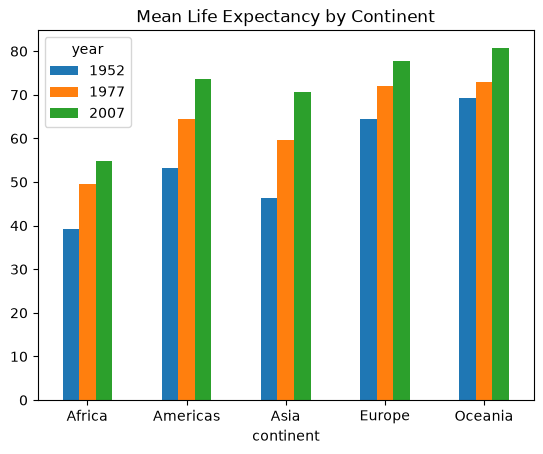

In [95]:
lifeExp_mean=(
    gap.query("year in [1952,1977,2007]")
              .groupby(['continent','year'])['lifeExp']
              .mean()
              .unstack()
             )

lifeExp_mean.plot.bar(rot=0, title="Mean Life Expectancy by Continent")
plt.show()

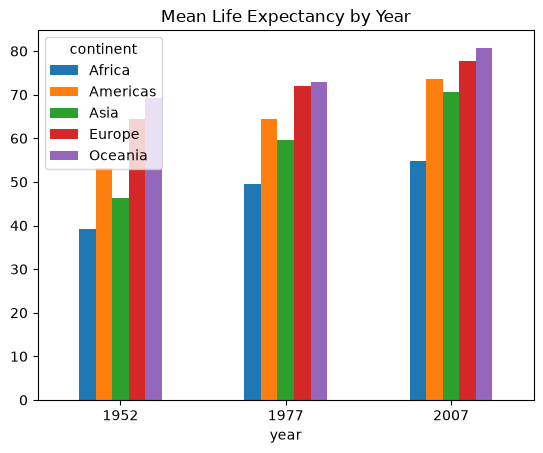

In [96]:
lifeExp_mean.T.plot.bar(rot=0, title="Mean Life Expectancy by Year")
plt.show()

**Question.** The two charts contain identical numbers. Which comparison does each one make easy,
and which continent's trajectory is hardest to read in the second chart? Why?

**Answer:**
The first chart makes it easy to compare how life expectancy changed over time by continent, while the second chart makes it easy to compare how life expectancy changes within a particular year across continents.

In the second chart, I think Europe's trajectory is the hardest to read because the bars are in between the bars of other graphis and require a lot of eye movement to track.

### Task 6

**Line graphs with two y axes.**

Create a **single** figure showing how mean life expectancy and mean GDP per capita have changed
over the whole period. Your plot must meet all of these requirements:

1. `year` on the x axis, using the mean across all countries for each year.
2. `lifeExp` on the **left** y axis, drawn as a red line.
3. `gdpPercap` on the **right** y axis, drawn as a blue line.
4. Both y axes labeled with their variable names.
5. A figure size of $10$ by $5$, a title, and legends that do not overlap each other.

> [!tip] Use `plt.twinx(ax)` or `ax.twinx()` to create the second axes object.

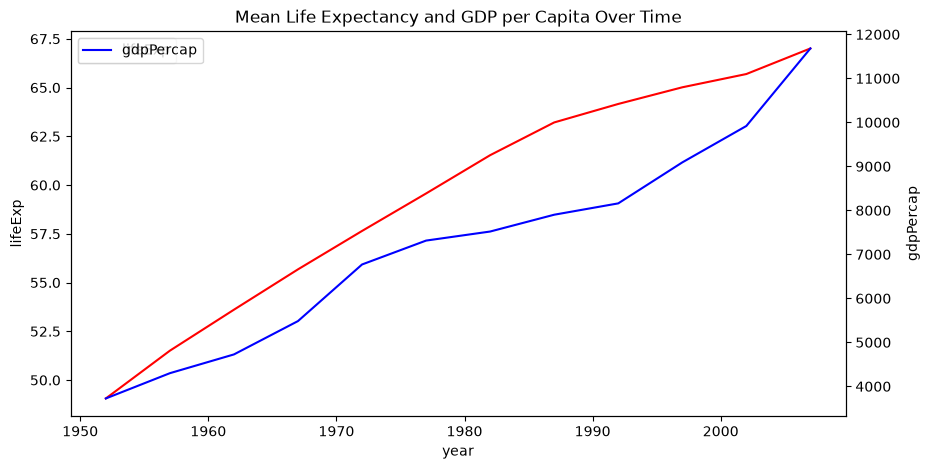

In [98]:
year_means = gap.groupby('year')[['lifeExp', 'gdpPercap']].mean()
ax = year_means['lifeExp'].plot(figsize=(10, 5), color='red', legend=True)
ax2 = ax.twinx()
year_means['gdpPercap'].plot(ax=ax2, color='blue', legend=True)
ax.set_ylabel('lifeExp'),ax2.set_ylabel('gdpPercap')
plt.title("Mean Life Expectancy and GDP per Capita Over Time")
plt.show()

### Task 7

**Area and difference charts** 

In Week 4 you built a difference chart of US agricultural imports and exports by
plotting two unstacked area charts and masking the overlap with a white area chart. Use that
pattern here.

1. Build a dataframe with `year` as the index and one column each for `Africa` and `Europe`, holding
   the mean `lifeExp` for that continent in that year.
2. Plot both columns as an **unstacked** area chart, figure size $12$ by $6$, with the y axis
   starting at $0$.
3. Turn it into a **difference chart** by plotting the row-wise minimum as a white area chart on the
   same axes.

> [!tip] The mask is `pair.min(axis=1)`, plotted with `.plot.area(ax=ax, color='white', lw=0)`.
>
> If you would rather use `ax.fill_between(..., where=...)`, that is also accepted for
> requirement $3$.

In [105]:
df_area=gap.query("continent in ['Africa','Europe']")
grouped_meanlifeExp=df_area.groupby(['year','continent'])['lifeExp'].mean()
final_meanlifeExp=grouped_meanlifeExp.unstack()
final_meanlifeExp

continent,Africa,Europe
year,,
1952,39.135500,64.408500
1957,41.266346,66.703067
1962,43.319442,68.539233
1967,45.334538,69.737600
1972,47.450942,70.775033
1977,49.580423,71.937767
1982,51.592865,72.806400
1987,53.344788,73.642167
1992,53.629577,74.440100


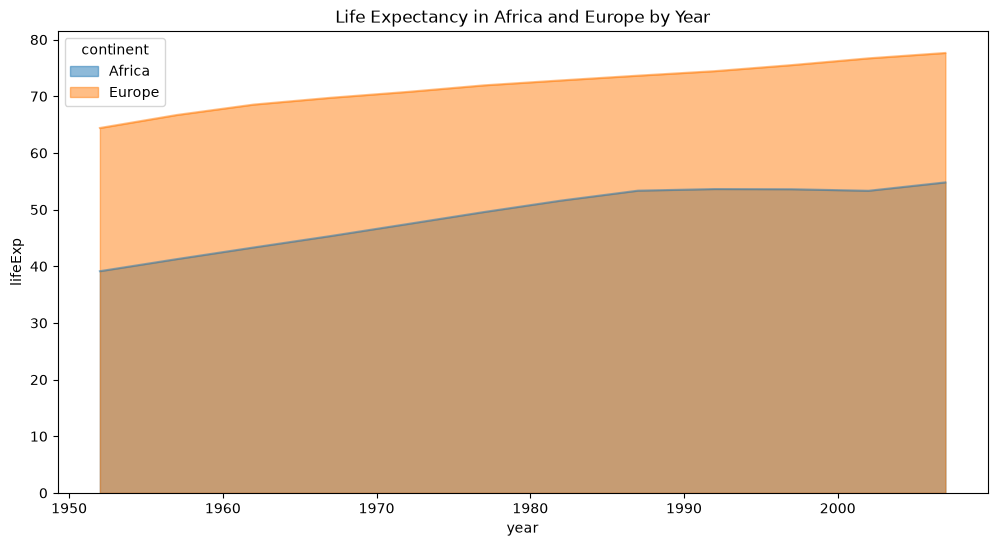

In [107]:
ax = final_meanlifeExp.plot.area(
    stacked=False, 
    figsize=(12, 6), 
    ylim=(0, None), 
    title="Life Expectancy in Africa and Europe by Year"
)

plt.ylabel("lifeExp")
plt.show()

<Figure size 1200x600 with 0 Axes>

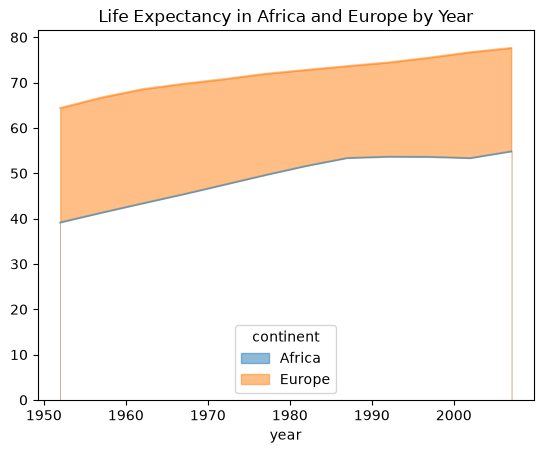

In [111]:
plt.figure(figsize=(12,6))
area_title = "Life Expectancy in Africa and Europe by Year"
ax = final_meanlifeExp.plot.area(stacked=False, ylim=(0,None), title=area_title)
mask = final_meanlifeExp.min(axis=1)
mask.plot.area(ax=ax, color='white', lw=0)
plt.show()

### Task 8

**Choosing the axis scale.**

Sort the $2007$ observations by `gdpPercap` from lowest to highest, reset the index, and plot the values as a line. The x axis is the rank of the country; the y axis is the value.

Then plot the same series again with `logy=True`.

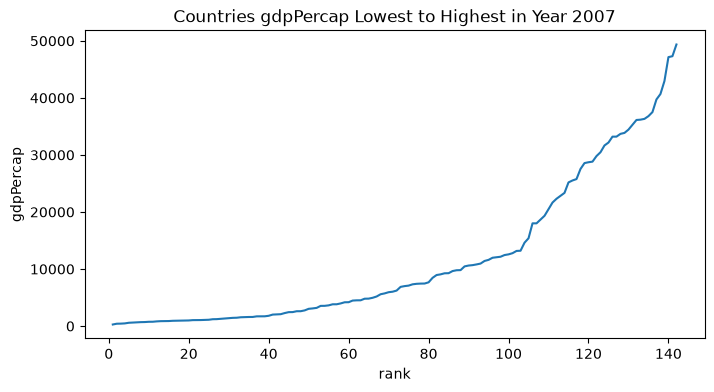

In [113]:
gap07['rank'] = gap07['gdpPercap'].rank(method='average', ascending=True)
df = gap07.sort_values('rank')

df.plot(x='rank', y='gdpPercap', figsize=(8, 4), title="Countries gdpPercap Lowest to Highest in Year 2007", legend=False)

plt.ylabel("gdpPercap")
plt.show()

### Task 9

**Creating an H-R diagram of nations.**

Use the **entire** `gap` dataframe, all $1{,}704$ observations, not just $2007$.

Create a scatter plot with `gdpPercap` on the x axis and `lifeExp` on the y axis.

Use a logarithmic x axis; pass `logx=True` to the plot method.

Use small, semi-transparent black points, since there are thousands of them. Try `s=3` and `alpha=0.3`.

Set the figure size of $8$ by $7$.

Set the title to "Life expectancy against income, 1952-2007".

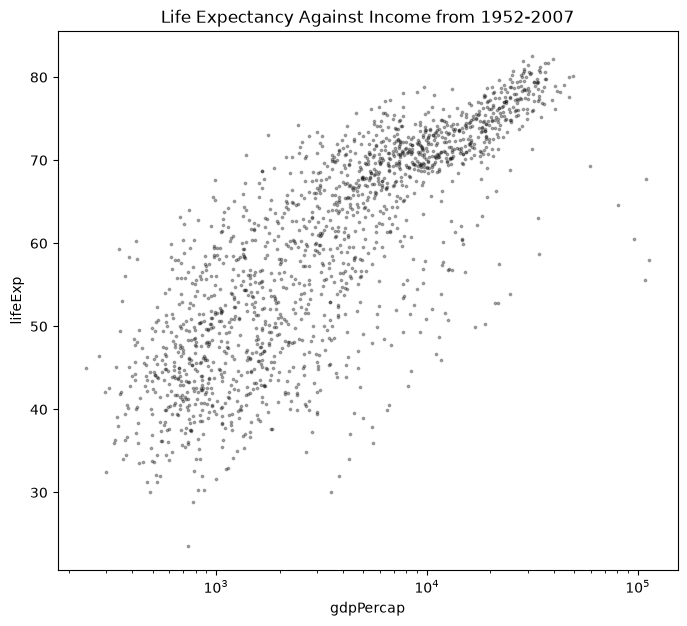

In [114]:
gap.plot.scatter(
    x='gdpPercap', y='lifeExp',s=3,alpha=0.3,c='black',figsize=(8, 7),
    title="Life Expectancy Against Income from 1952-2007",logx=True)

plt.ylabel("lifeExp")
plt.show()

### Task 10

Recreate the preceding plot with the following changes:

Wrap the plotting code in `with plt.style.context("dark_background"):` so the figure gets a dark background.

Color each point by `log_gdppc` using a blue-to-red colormap. Try `cmap="RdYlBu_r"`.

Size each point by `pop_m` so that populous countries read as bright, heavy points. Scale the values so that the largest circles do not swallow the plot — `s=gap['pop_m'] / 2` is a reasonable starting point.

Set `linewidths=0`, a figure size of $11$ by $8$, an alpha around $0.6$.

Finally, set the title to "The wealth and health of nations, 1952-2007".

In [ ]:
with plt.style.context("dark_background"):
    gap.plot.scatter(
        x='gdpPercap', 
        y='lifeExp',
        s=gap['pop_m'] / 2,
        alpha=0.6,
        c='log_gdppc',
        cmap="RdYlBu_r",
        linewidths=0,
        figsize=(11, 8),
        title="The wealth and health of nations, 1952-2007",
        logx=True,
        legend=False
    )
    plt.show()